# Grafici per la presentazione (non corner)

Figure della presentazione che non sono corner plot. Salvate in `Presentazione/Figure/`; le figure della tesi non vengono toccate.

1. Curva di Hellings–Downs, con etichette in italiano
2. Densità spettrale di potenza (PSD) a legge di potenza: GWB e rumori del modello di J1640+2224

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pyarrow.feather as feather

CARTELLA = 'Presentazione/Figure'
os.makedirs(CARTELLA, exist_ok=True)

REALE = '#2E86AB'   # blu
SIM   = '#F4A261'   # arancio
SIM_2 = '#6A4C93'   # viola
NERO  = '#222222'

plt.rcParams.update({'font.size': 13, 'axes.labelsize': 15, 'legend.fontsize': 12})

## 1. Curva di Hellings–Downs

Stessa formula di `Tesi_LaTeX/script/fig_hellings_downs.py`; sull'asse x la separazione angolare tra le due pulsar.

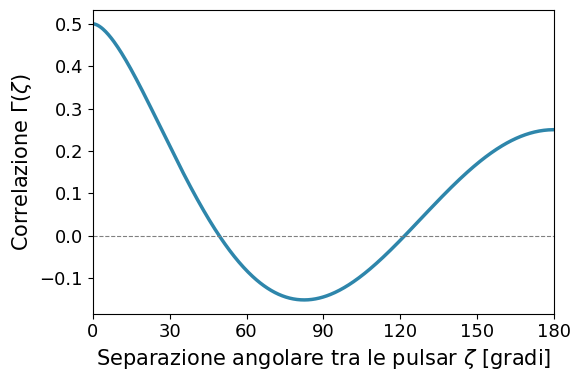

In [2]:
zeta = np.linspace(1e-6, np.pi, 500)            # separazione angolare [rad]
x = (1 - np.cos(zeta)) / 2
gamma_hd = 0.5 - x / 4 + 1.5 * x * np.log(x)    # Eq. (HD) del Capitolo 2

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.degrees(zeta), gamma_hd, color=REALE, lw=2.5)
ax.axhline(0, color='grey', lw=0.8, ls='--')
ax.set_xlabel(r'Separazione angolare tra le pulsar $\zeta$ [gradi]')
ax.set_ylabel(r'Correlazione $\Gamma(\zeta)$')
ax.set_xlim(0, 180)
ax.set_xticks(range(0, 181, 30))
fig.tight_layout()
fig.savefig(f'{CARTELLA}/P02_hellings_downs.pdf')
fig.savefig(f'{CARTELLA}/P02_hellings_downs.png', dpi=150)

## 2. PSD a legge di potenza del GWB

Formula della tesi (Cap. 3): $S(f) = \frac{A^2}{12\pi^2}\left(\frac{f}{f_{\rm yr}}\right)^{-\gamma} f_{\rm yr}^{-3}$ (s³), la stessa di `discovery_new.powerlaw` senza il fattore $\Delta f$.

Solo il **GWB**: $\gamma = 13/3$, $\log_{10}A = -14.5$ (una delle ampiezze della sez. 5.2.2).
Frequenze da $1/T$ a $30/T$, con $T$ = durata dei dati DR2low di J1640+2224.

T = 12.2 anni,  f da 2.61e-09 a 7.82e-08 Hz


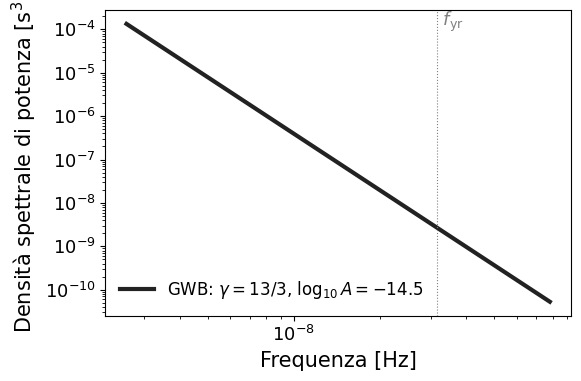

In [5]:
# durata dei dati di J1640+2224 (DR2low)
toas = feather.read_table('./dati/DR2low_feathers/J1640+2224', columns=['toas']).to_pandas()['toas']
T = toas.max() - toas.min()                      # [s]
fyr = 1 / (365.25 * 86400)                       # [Hz]
f = np.logspace(np.log10(1 / T), np.log10(30 / T), 300)
print(f'T = {T/86400/365.25:.1f} anni,  f da {f[0]:.2e} a {f[-1]:.2e} Hz')

def psd(log10_A, gamma):
    return (10**log10_A)**2 / (12 * np.pi**2) * (f / fyr)**(-gamma) * fyr**(-3)

# solo il GWB: gamma = 13/3, log10_A = -14.5
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(f, psd(-14.5, 13/3), color=NERO, lw=3,
          label=r'GWB: $\gamma = 13/3$, $\log_{10}A = -14.5$')
ax.axvline(fyr, color='grey', lw=0.8, ls=':')
ax.text(fyr, ax.get_ylim()[1], r' $f_{\rm yr}$', va='top', ha='left', color='grey', fontsize=13)
ax.set_xlabel('Frequenza [Hz]')
ax.set_ylabel(r'Densità spettrale di potenza [s$^3$]')
ax.legend(frameon=False, loc='lower left')
fig.tight_layout()
fig.savefig(f'{CARTELLA}/P02_power_law.pdf')
fig.savefig(f'{CARTELLA}/P02_power_law.png', dpi=150)